# 7CS353 Machine Learning Lab — Assignment 8
### Decision Tree and Random Forest Classification

Name: Atharv V Kulkarni
PRN: 245109074
Class: TY CSE(B)

## B1. Load and explore

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
np.random.seed(42)

In [2]:
iris = load_iris()
x = iris.data
y = iris.target
feature_names = iris.feature_names
class_names = iris.target_names
df = pd.DataFrame(x, columns=feature_names)
df["species"] = pd.Categorical.from_codes(y, class_names)
print(df.shape)
print(df["species"].value_counts())
print(df.describe())

(150, 5)
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)  
count        150.000000  
mean           1.199333  
std            0.762238  
min            0.100000  
25%            0.300000  
50%            1.300000  
75%            1.800000  
max            2.500000  


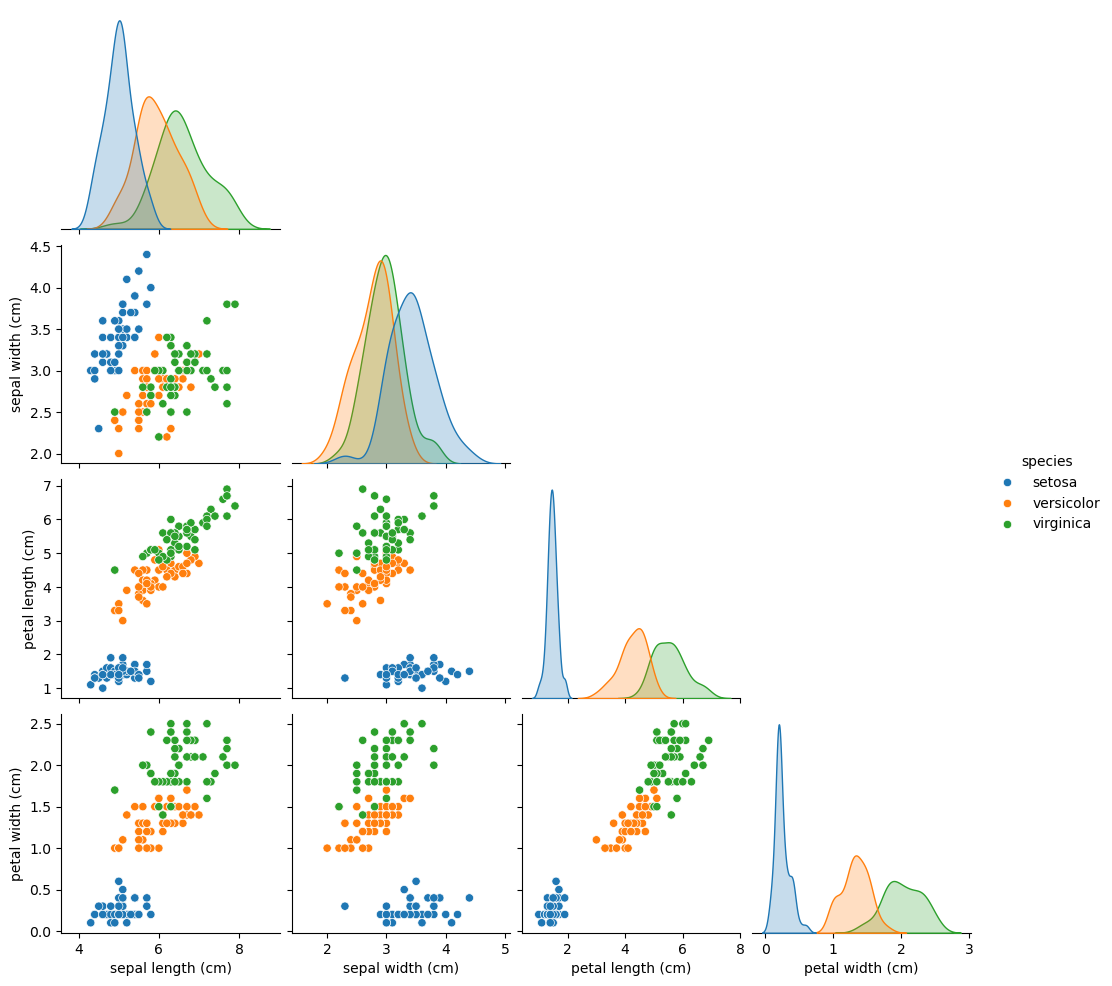

In [3]:
sns.pairplot(df, hue="species", corner=True)
plt.show()

## B2. Impurity from scratch

In [4]:
def entropy(labels):
    _, counts = np.unique(labels, return_counts=True)
    p = counts / counts.sum()
    return -np.sum(p * np.log2(p))

def gini(labels):
    _, counts = np.unique(labels, return_counts=True)
    p = counts / counts.sum()
    return 1 - np.sum(p**2)

In [5]:
petal_length = x[:, 2]
mask = petal_length <= 2.45
left = y[mask]
right = y[~mask]

h_parent = entropy(y)
h_left = entropy(left)
h_right = entropy(right)
info_gain = h_parent - (len(left)/len(y))*h_left - (len(right)/len(y))*h_right

print("entropy full set:", h_parent, "gini full set:", gini(y))
print("entropy left (petal_length<=2.45):", h_left, "gini left:", gini(left))
print("entropy right (petal_length>2.45):", h_right, "gini right:", gini(right))
print("information gain:", info_gain)

entropy full set: 1.584962500721156 gini full set: 0.6666666666666667
entropy left (petal_length<=2.45): -0.0 gini left: 0.0
entropy right (petal_length>2.45): 1.0 gini right: 0.5
information gain: 0.9182958340544894


## B3. Decision tree — fit and visualise

In [6]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
dt = DecisionTreeClassifier(max_depth=3, criterion="entropy", random_state=42)
dt.fit(x_train, y_train)

,criterion,'entropy'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


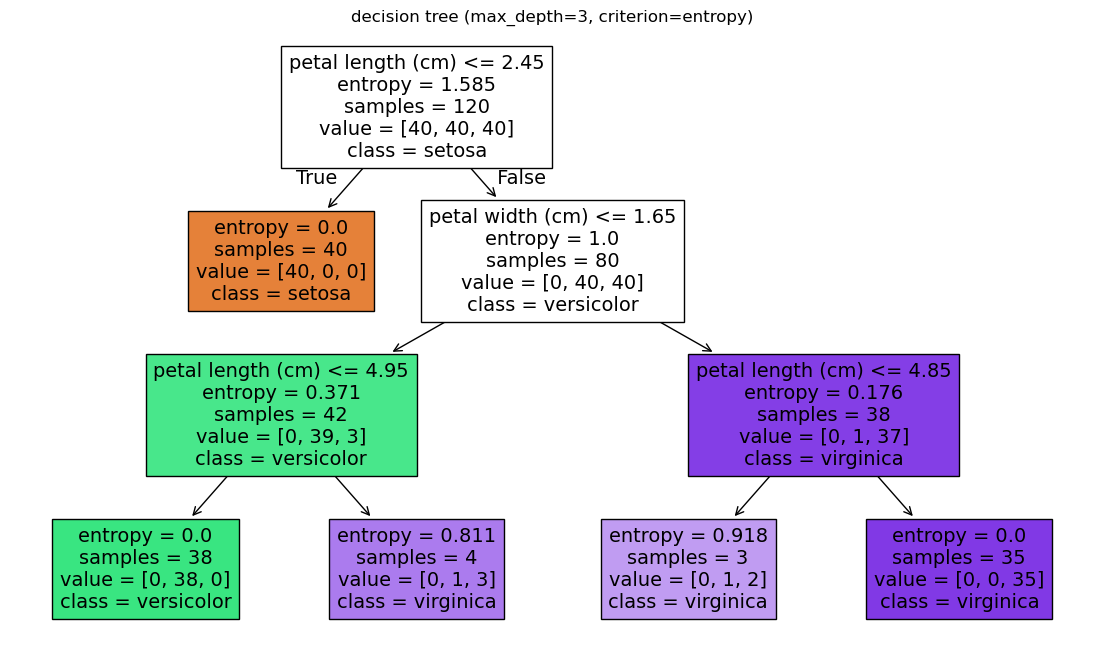

In [7]:
fig, ax = plt.subplots(figsize=(14,8))
plot_tree(dt, feature_names=feature_names, class_names=class_names, filled=True, ax=ax)
ax.set_title("decision tree (max_depth=3, criterion=entropy)")
plt.show()

In [8]:
print(export_text(dt, feature_names=feature_names))

|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.65
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- class: 1
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- class: 2
|   |--- petal width (cm) >  1.65
|   |   |--- petal length (cm) <= 4.85
|   |   |   |--- class: 2
|   |   |--- petal length (cm) >  4.85
|   |   |   |--- class: 2



In [9]:
y_pred_dt = dt.predict(x_test)
print(classification_report(y_test, y_pred_dt, target_names=class_names))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



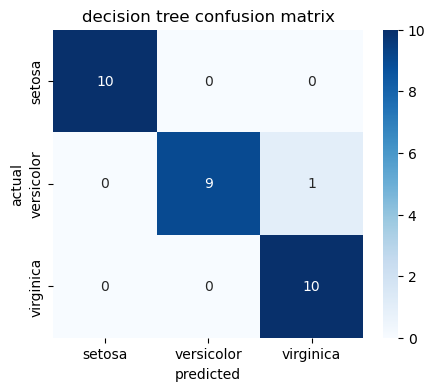

In [10]:
cm_dt = confusion_matrix(y_test, y_pred_dt)
fig, ax = plt.subplots(figsize=(5,4))
sns.heatmap(cm_dt, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.set_xlabel("predicted")
ax.set_ylabel("actual")
ax.set_title("decision tree confusion matrix")
plt.show()

## B4. Depth analysis

In [11]:
train_acc = []
test_acc = []
depths = range(1, 11)
for depth in depths:
    model = DecisionTreeClassifier(max_depth=depth, criterion="entropy", random_state=42)
    model.fit(x_train, y_train)
    train_acc.append(accuracy_score(y_train, model.predict(x_train)))
    test_acc.append(accuracy_score(y_test, model.predict(x_test)))

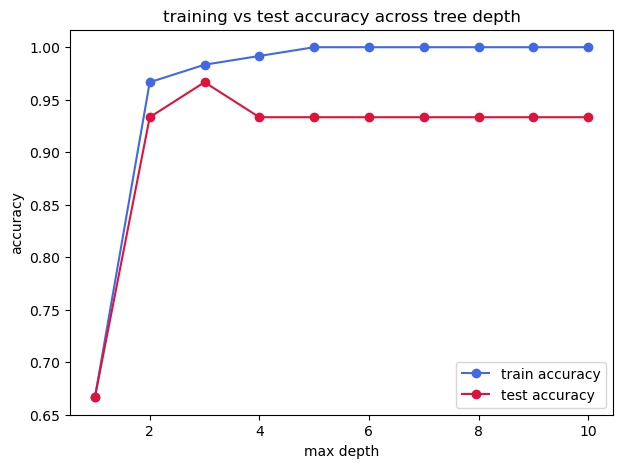

In [12]:
fig, ax = plt.subplots(figsize=(7,5))
ax.plot(list(depths), train_acc, marker="o", label="train accuracy", color="royalblue")
ax.plot(list(depths), test_acc, marker="o", label="test accuracy", color="crimson")
ax.set_xlabel("max depth")
ax.set_ylabel("accuracy")
ax.set_title("training vs test accuracy across tree depth")
ax.legend()
plt.show()

## B5. Random forest — fit and evaluate

In [13]:
rf = RandomForestClassifier(n_estimators=100, oob_score=True, random_state=42)
rf.fit(x_train, y_train)
print("oob score:", rf.oob_score_)
y_pred_rf = rf.predict(x_test)
print(classification_report(y_test, y_pred_rf, target_names=class_names))

oob score: 0.9416666666666667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



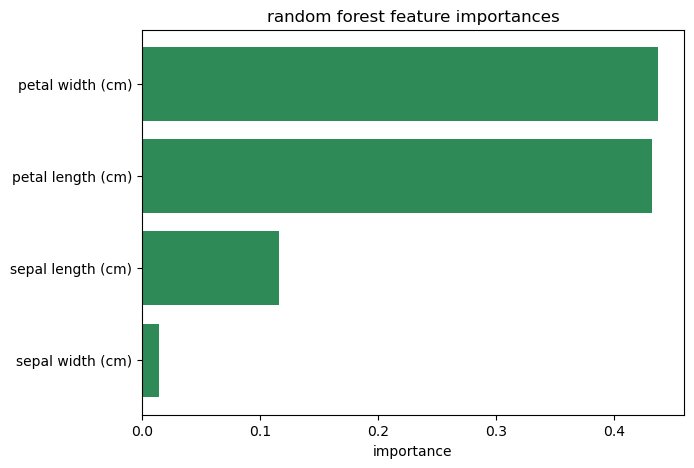

In [14]:
importances = pd.Series(rf.feature_importances_, index=feature_names).sort_values()
fig, ax = plt.subplots(figsize=(7,5))
ax.barh(importances.index, importances.values, color="seagreen")
ax.set_xlabel("importance")
ax.set_title("random forest feature importances")
plt.show()

## B6. Hyperparameter tuning

In [15]:
param_grid = {"n_estimators": [50, 100, 200], "max_depth": [None, 5, 10, 15]}
grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=5)
grid.fit(x_train, y_train)
print("best params:", grid.best_params_)
print("best cv accuracy:", grid.best_score_)

best params: {'max_depth': None, 'n_estimators': 50}
best cv accuracy: 0.95


In [16]:
rf_tuned = grid.best_estimator_
y_pred_tuned = rf_tuned.predict(x_test)
print(classification_report(y_test, y_pred_tuned, target_names=class_names))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



## B7. Comparison and interpretation

In [17]:
def metrics_row(y_true, y_pred):
    return (accuracy_score(y_true, y_pred),
            precision_score(y_true, y_pred, average="macro"),
            recall_score(y_true, y_pred, average="macro"),
            f1_score(y_true, y_pred, average="macro"))

print("decision tree (depth=3):", metrics_row(y_test, y_pred_dt))
print("random forest (default):", metrics_row(y_test, y_pred_rf))
print("random forest (tuned):", metrics_row(y_test, y_pred_tuned))

decision tree (depth=3): (0.9666666666666667, 0.9696969696969697, 0.9666666666666667, 0.9665831244778612)
random forest (default): (0.9, 0.9023569023569024, 0.9, 0.899749373433584)
random forest (tuned): (0.9, 0.9023569023569024, 0.9, 0.899749373433584)


In [2]:
# Model	                    Test accuracy	   Macro precision	Macro recall	Macro F1
# Decision Tree, depth 3	  96.67%	               96.97%	96.67%	         96.66%
# Random Forest, default	  90.00%	               90.24%	90.00%	         89.97%
# Random Forest, tuned	      90.00%	               90.24%	90.00%	         89.97%